In [1]:
import inspect
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mean_variance
import pull_crsp

In [2]:
df = pull_crsp.load_extract()

In [3]:
df.tail()

,AAPL,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,KO,WMT,CAT,BA,MKT,RF
date,,,,,,,,,,,,,,
2024-08-31,0.032345,-0.001116,-0.045352,0.020082,0.056391,0.002476,0.058740,0.067057,0.085856,0.128324,0.028596,-0.088458,0.022022,0.0048
2024-09-30,0.017467,0.031548,0.043866,0.017426,-0.062011,-0.006105,-0.022911,0.009677,-0.001683,0.045578,0.098343,-0.124899,0.021040,0.0040
2024-10-31,-0.030429,-0.055659,0.000376,0.093215,0.058680,-0.003754,-0.013575,-0.040701,-0.091150,0.014861,-0.034674,-0.017956,-0.007766,0.0039
2024-11-30,0.051708,0.044202,0.115290,0.041353,0.125270,0.018399,-0.022558,0.085240,-0.011407,0.128737,0.079506,0.041056,0.066560,0.0040
2024-12-31,0.055155,-0.004629,0.055318,-0.028577,-0.040085,-0.088081,-0.067028,-0.064766,-0.028402,-0.021093,-0.106744,0.138703,-0.031325,0.0037


In [4]:
stocks = df.drop(columns=["MKT", "RF"])
rf = df["RF"].mean()

summary = pd.DataFrame(
    {
        "mean (annualized)": 12*stocks.mean(),
        "volatility (annualized)": np.sqrt(12)*stocks.std(),
    }  
)
summary["Sharpe Ratio"] = (summary["mean (annualized)"] - rf) / summary["volatility (annualized)"]
summary.round(2)

,mean (annualized),volatility (annualized),Sharpe Ratio
AAPL,0.31,0.38,0.81
MSFT,0.14,0.28,0.49
AMZN,0.26,0.44,0.58
NVDA,0.47,0.60,0.78
JPM,0.13,0.30,0.45
XOM,0.09,0.22,0.43
JNJ,0.08,0.16,0.51
PG,0.09,0.18,0.49
KO,0.07,0.17,0.42
WMT,0.09,0.19,0.47


Text(0.5, 1.0, 'Cumulative returns, 2000-2024')

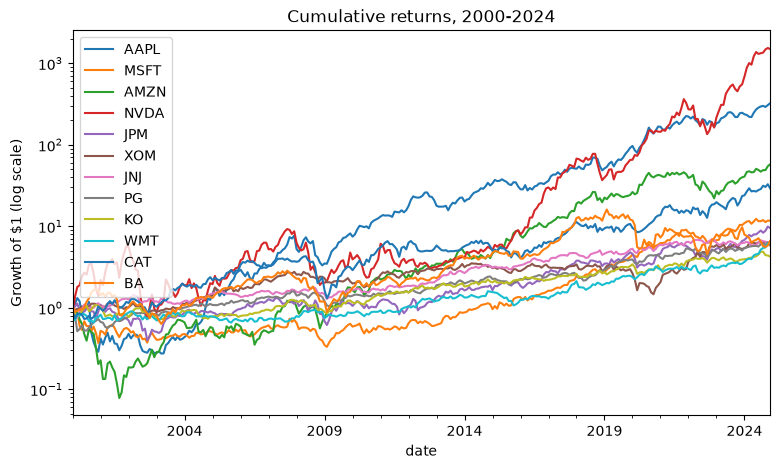

In [5]:
(1+stocks).cumprod().plot(logy=True, figsize=(9, 5))
plt.ylabel("Growth of $1 (log scale)")
plt.title("Cumulative returns, 2000-2024")

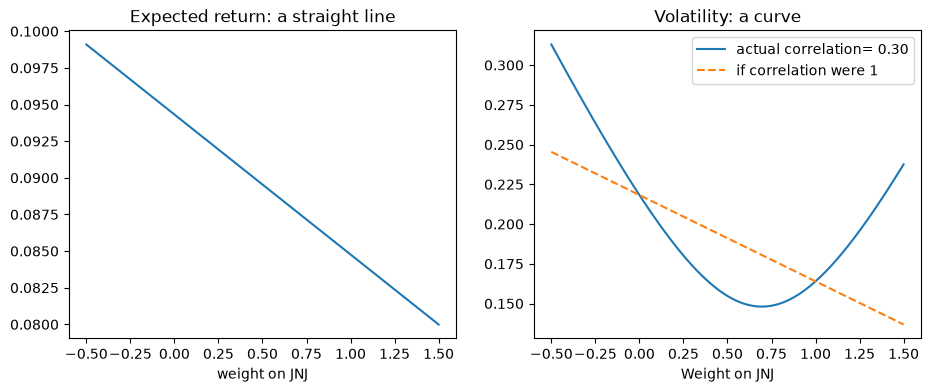

In [6]:
a,b = "JNJ", "XOM"
mu_a, mu_b = stocks[a].mean(), stocks[b].mean()
sd_a, sd_b = stocks[a].std(), stocks[b].std()
rho = stocks[a].corr(stocks[b])

w = np.linspace(-0.5, 1.5, 201)
mean_p = w*mu_a + (1-w) * mu_b
sd_p = np.sqrt(w**2 *sd_a**2 + (1-w)**2 * sd_b**2 + 2*w*(1-w)*rho*sd_a*sd_b)
sd_if_perfectly_correlated = np.abs(w*sd_a + (1-w)*sd_b)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(w, 12*mean_p)
axes[0].set_title("Expected return: a straight line")
axes[0].set_xlabel(f"weight on {a}")
axes[1].plot(w, np.sqrt(12)*sd_p, label = f"actual correlation= {rho:.2f}")
axes[1].plot(
    w,
    np.sqrt(12) * sd_if_perfectly_correlated,
    linestyle="--",
    label = "if correlation were 1",
)
axes[1].set_title("Volatility: a curve")
axes[1].set_xlabel(f"Weight on {a}")
axes[1].legend();


In [7]:
mu = stocks.mean().values
Sigma  = stocks.cov().values
ones = np.ones(len(mu))

w_gmv = np.linalg.solve(Sigma, ones)
w_gmv = w_gmv / w_gmv.sum()

w_tan = np.linalg.solve(Sigma, mu-rf)
w_tan = w_tan / w_tan.sum()

pd.DataFrame({'GMV':w_gmv, "Tangency": w_tan}, index=stocks.columns).round(3)

,GMV,Tangency
AAPL,0.047,0.242
MSFT,0.055,-0.106
AMZN,0.003,0.040
NVDA,0.001,0.143
JPM,0.015,-0.041
XOM,0.162,0.021
JNJ,0.187,0.136
PG,0.242,0.304
KO,0.121,0.012
WMT,0.221,0.146


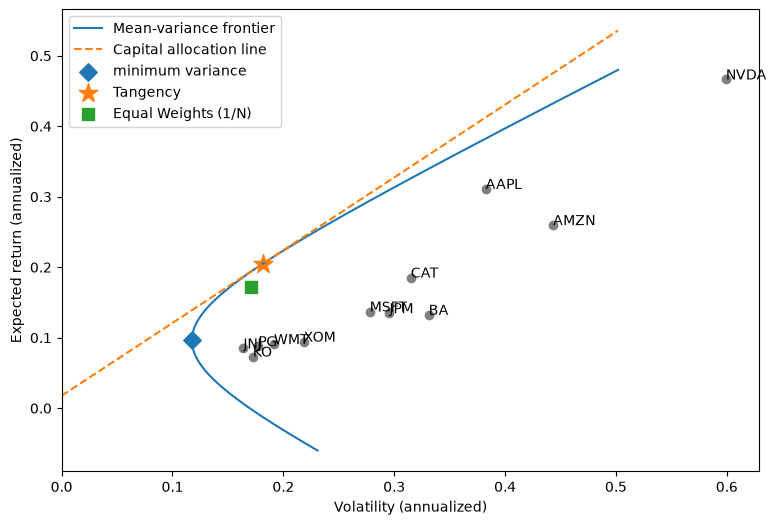

In [8]:
targets = np.linspace(-.005, 0.04, 200)
frontier_vol = np.sqrt(mean_variance.frontier_variance(mu, Sigma, targets))

def annualized_mean_and_vol(weights):
    return 12*weights@mu, np.sqrt(12*weights@Sigma@weights)

mean_gmv, vol_gmv = annualized_mean_and_vol(w_gmv)
mean_tan, vol_tan = annualized_mean_and_vol(w_tan)
mean_ew, vol_ew = annualized_mean_and_vol(ones / len(ones))

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(np.sqrt(12) * frontier_vol, 12 * targets, label="Mean-variance frontier")
vol_grid = np.linspace(0, np.sqrt(12)*frontier_vol.max(), 50)
ax.plot(vol_grid,
        12* rf + (mean_tan - 12*rf) / vol_tan*vol_grid,
        linestyle="--",
        label = "Capital allocation line")
ax.scatter(summary["volatility (annualized)"], summary["mean (annualized)"], color= "gray")
for ticker, row in summary.iterrows():
    ax.annotate(ticker, (row["volatility (annualized)"], row["mean (annualized)"]))

ax.scatter(vol_gmv, mean_gmv, marker="D", s=80, label = "minimum variance")
ax.scatter(vol_tan, mean_tan, marker = "*", s=200, label="Tangency")
ax.scatter(vol_ew, mean_ew, marker = "s", s=80, label="Equal Weights (1/N)")
ax.set_xlabel("Volatility (annualized)")
ax.set_ylabel("Expected return (annualized)")
ax.set_xlim(left=0)
ax.legend()

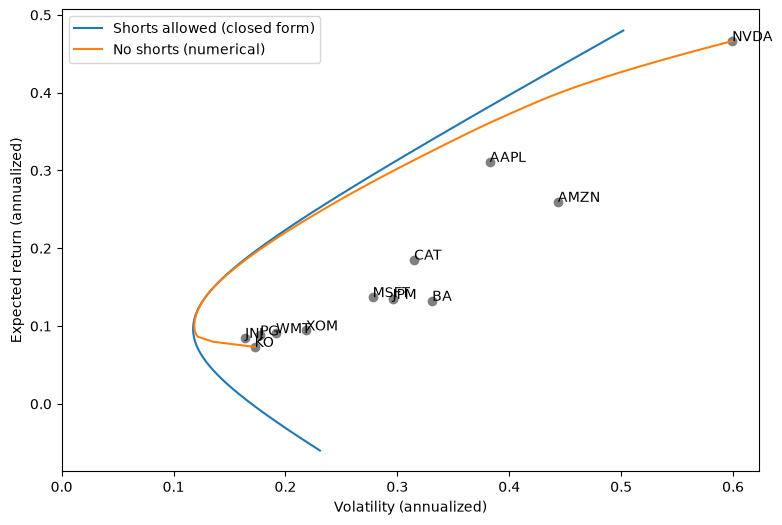

In [9]:
targets_no_short = np.linspace(mu.min(), mu.max(), 60)
weights_no_short = mean_variance.frontier(mu, Sigma, targets_no_short, allow_short=False)
vol_no_short = np.sqrt([w@Sigma@w for w in weights_no_short])

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(np.sqrt(12)*frontier_vol, 12*targets, label="Shorts allowed (closed form)")
ax.plot(np.sqrt(12)*vol_no_short, 12*targets_no_short, label="No shorts (numerical)")
ax.scatter(summary["volatility (annualized)"], summary["mean (annualized)"], color="gray")
for ticker, row in summary.iterrows():
    ax.annotate(ticker, (row["volatility (annualized)"], row["mean (annualized)"]))
ax.set_xlabel("Volatility (annualized)")
ax.set_ylabel("Expected return (annualized)")
ax.set_xlim(left=0)
ax.legend();

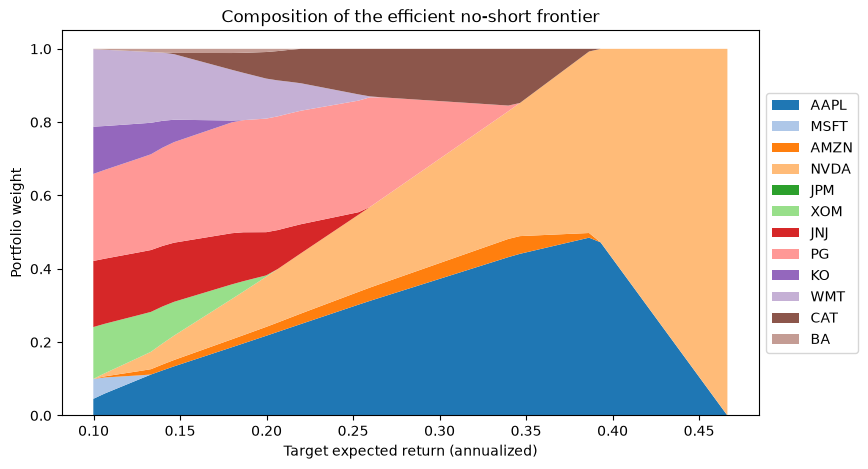

In [10]:
efficient = targets_no_short >= weights_no_short[np.argmin(vol_no_short)]@mu
fig, ax = plt.subplots(figsize=(9, 5))
ax.stackplot(
    12*targets_no_short[efficient],
    weights_no_short[efficient].T,
    labels=stocks.columns,
    colors = plt.cm.tab20.colors
)
ax.set_xlabel("Target expected return (annualized)")
ax.set_ylabel("Portfolio weight")
ax.set_title("Composition of the efficient no-short frontier")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5));

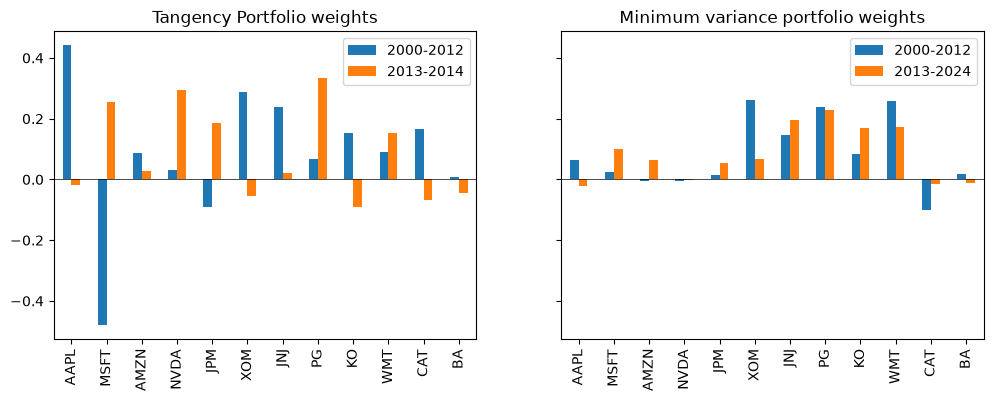

In [20]:
def tangency_weights(returns, rf):
    w = np.linalg.solve(returns.cov().values, returns.mean().values - rf)
    return pd.Series(w/w.sum(), index=returns.columns)

def gmv_weights(returns):
    w = np.linalg.solve(returns.cov().values, np.ones(returns.shape[1]))
    return pd.Series(w/w.sum(), index=returns.columns)

first, second = stocks.loc[:"2012"], stocks.loc["2013":]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
pd.DataFrame({"2000-2012": tangency_weights(first, rf), "2013-2014": tangency_weights(second, rf)}
).plot.bar(ax=axes[0], title="Tangency Portfolio weights")
pd.DataFrame({"2000-2012":gmv_weights(first), "2013-2024":gmv_weights(second)}
).plot.bar(ax=axes[1], title="Minimum variance portfolio weights")
axes[0].axhline(0, color="black", linewidth=0.5)
axes[1].axhline(0, color="black", linewidth=0.5)